In [264]:
from pathlib import Path

for file in Path("..").rglob("*placement*.csv"):
    print("File:", file.name)
    print("Full path:", file.resolve())
    print("Size:", round(file.stat().st_size / 1024, 2), "KB")

File: student_placement_3000.csv
Full path: C:\Users\prani\OneDrive\Desktop\lpu-placement-intelligence\Lpu-Placement-intelligence\data\processed\student_placement_3000.csv
Size: 150.46 KB
File: student_placement_synthetic (1).csv
Full path: C:\Users\prani\OneDrive\Desktop\lpu-placement-intelligence\Lpu-Placement-intelligence\data\raw\student_placement_synthetic (1).csv
Size: 5982.98 KB


In [265]:
import pandas as pd
from pathlib import Path

files = list(Path("..").rglob("student_placement_synthetic*.csv"))

if not files:
    print("Dataset not found!")
else:
    file_path = files[0]
    df = pd.read_csv(file_path)

    print("Dataset loaded successfully!")
    print("File:", file_path.name)
    print("Dataset shape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFirst 5 records:")
    display(df.head())

Dataset loaded successfully!
File: student_placement_synthetic (1).csv
Dataset shape: (100000, 18)

Columns:
['branch', 'college_tier', 'cgpa', 'backlogs', 'coding_skills', 'dsa_score', 'aptitude_score', 'communication_skills', 'ml_knowledge', 'system_design', 'internships', 'projects_count', 'certifications', 'hackathons', 'open_source_contributions', 'extracurriculars', 'placement_status', 'salary_package_lpa']

First 5 records:


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [ ]:
# 1. Dataset dimensions
print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])

# 2. Missing values
print("\nMissing values:")
print(df.isnull().sum())

# 3. Duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# 4. Data types
print("\nData types:")
print(df.dtypes)

# 5. Placement distribution
print("\nPlacement status distribution:")
print(df["placement_status"].value_counts())

# 6. Statistical summary
print("\nStatistical summary:")
display(df.describe(include="all").T)

Total records: 100000
Total columns: 18

Missing values:
branch                           0
college_tier                     0
cgpa                             0
backlogs                         0
coding_skills                    0
dsa_score                        0
aptitude_score                   0
communication_skills             0
ml_knowledge                     0
system_design                    0
internships                      0
projects_count                   0
certifications                   0
hackathons                       0
open_source_contributions        0
extracurriculars                 0
placement_status                 0
salary_package_lpa           31525
dtype: int64

Duplicate records: 0

Data types:
branch                           str
college_tier                     str
cgpa                         float64
backlogs                       int64
coding_skills                float64
dsa_score                    float64
aptitude_score               float64
commun

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
branch,100000,7,CSE,25046,NaN,NaN,NaN,NaN,NaN,NaN,NaN
college_tier,100000,3,Tier-3,45222,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cgpa,100000.0,NaN,NaN,NaN,7.206381,0.925235,4.0,6.58,7.21,7.83,10.0
backlogs,100000.0,NaN,NaN,NaN,0.54701,0.862727,0.0,0.0,0.0,1.0,3.0
coding_skills,100000.0,NaN,NaN,NaN,5.995147,1.496302,1.0,5.0,6.0,7.0,10.0
dsa_score,100000.0,NaN,NaN,NaN,5.500711,1.781961,1.0,4.3,5.5,6.7,10.0
aptitude_score,100000.0,NaN,NaN,NaN,64.990511,11.990892,20.0,56.8,65.0,73.1,100.0
communication_skills,100000.0,NaN,NaN,NaN,5.990614,1.496552,1.0,5.0,6.0,7.0,10.0
ml_knowledge,100000.0,NaN,NaN,NaN,4.508752,1.968278,0.0,3.2,4.5,5.9,10.0
system_design,100000.0,NaN,NaN,NaN,4.00821,1.778405,0.0,2.8,4.0,5.2,10.0


In [ ]:
print("PLACEMENT DISTRIBUTION")
print(df["placement_status"].value_counts(dropna=False))

print("\nPLACEMENT PERCENTAGE")
print(df["placement_status"].value_counts(normalize=True) * 100)

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nSALARY BY PLACEMENT STATUS")
print(df.groupby("placement_status")["salary_package_lpa"].agg(
    ["count", "mean", "min", "max"]
))

PLACEMENT DISTRIBUTION
placement_status
1    68475
0    31525
Name: count, dtype: int64

PLACEMENT PERCENTAGE
placement_status
1    68.475
0    31.525
Name: proportion, dtype: float64

MISSING VALUES
branch                           0
college_tier                     0
cgpa                             0
backlogs                         0
coding_skills                    0
dsa_score                        0
aptitude_score                   0
communication_skills             0
ml_knowledge                     0
system_design                    0
internships                      0
projects_count                   0
certifications                   0
hackathons                       0
open_source_contributions        0
extracurriculars                 0
placement_status                 0
salary_package_lpa           31525
dtype: int64

SALARY BY PLACEMENT STATUS
                  count       mean   min    max
placement_status                               
0                     0        Na

In [ ]:
from sklearn.model_selection import train_test_split
from pathlib import Path

# Create a representative 3,000-record sample
df_3000, _ = train_test_split(
    df,
    train_size=3000,
    stratify=df["placement_status"],
    random_state=42
)

# Shuffle the selected records
df_3000 = df_3000.sample(frac=1, random_state=42).reset_index(drop=True)

# Create processed folder
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the dataset
output_path = output_dir / "student_placement_3000.csv"
df_3000.to_csv(output_path, index=False)

print("Dataset created successfully!")
print("Total records:", len(df_3000))
print("\nPlacement distribution:")
print(df_3000["placement_status"].value_counts())
print("\nSaved at:", output_path.resolve())

Dataset created successfully!
Total records: 3000

Placement distribution:
placement_status
1    2054
0     946
Name: count, dtype: int64

Saved at: C:\Users\prani\OneDrive\Desktop\lpu-placement-intelligence\Lpu-Placement-intelligence\data\processed\student_placement_3000.csv


In [ ]:
import pandas as pd
from pathlib import Path

file_path = Path("../data/processed/student_placement_3000.csv")

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (3000, 18)

Columns:
['branch', 'college_tier', 'cgpa', 'backlogs', 'coding_skills', 'dsa_score', 'aptitude_score', 'communication_skills', 'ml_knowledge', 'system_design', 'internships', 'projects_count', 'certifications', 'hackathons', 'open_source_contributions', 'extracurriculars', 'placement_status', 'salary_package_lpa']


,branch,college_tier,cgpa,backlogs,coding_skills,dsa_score,aptitude_score,communication_skills,ml_knowledge,system_design,internships,projects_count,certifications,hackathons,open_source_contributions,extracurriculars,placement_status,salary_package_lpa
0,CE,Tier-3,6.36,0,6.3,4.3,60.0,5.1,4.6,6.0,2,3,2,0,2,0,0,NaN
1,CSE,Tier-2,8.85,3,7.0,8.0,75.2,3.8,6.0,4.1,1,5,2,0,0,0,1,21.95
2,EE,Tier-3,6.24,1,6.7,2.9,61.2,4.9,6.2,7.1,1,1,1,2,1,3,1,16.00
3,CSE,Tier-3,5.70,1,7.4,1.0,77.6,6.6,4.8,6.9,2,4,2,0,0,0,1,16.59
4,ME,Tier-1,7.86,1,6.8,4.8,68.7,5.1,7.8,4.9,0,5,2,1,0,0,0,NaN


In [ ]:
# Remove unwanted columns
df = df.drop(columns=["college_tier", "system_design"])

# Verify
print("Updated dataset shape:", df.shape)
print("\nRemaining columns:")
print(df.columns.tolist())

Updated dataset shape: (3000, 16)

Remaining columns:
['branch', 'cgpa', 'backlogs', 'coding_skills', 'dsa_score', 'aptitude_score', 'communication_skills', 'ml_knowledge', 'internships', 'projects_count', 'certifications', 'hackathons', 'open_source_contributions', 'extracurriculars', 'placement_status', 'salary_package_lpa']


In [ ]:
# Save the cleaned dataset
output_path = Path("../data/processed/student_placement_3000.csv")

df.to_csv(output_path, index=False)

print("Dataset saved successfully!")
print("Final shape:", df.shape)
print("Saved location:", output_path.resolve())

Dataset saved successfully!
Final shape: (3000, 16)
Saved location: C:\Users\prani\OneDrive\Desktop\lpu-placement-intelligence\Lpu-Placement-intelligence\data\processed\student_placement_3000.csv


In [ ]:
# Check dataset quality

print("DATASET INFORMATION")
df.info()

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())

print("\nSTATISTICAL SUMMARY")
display(df.describe())

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   branch                     3000 non-null   str    
 1   cgpa                       3000 non-null   float64
 2   backlogs                   3000 non-null   int64  
 3   coding_skills              3000 non-null   float64
 4   dsa_score                  3000 non-null   float64
 5   aptitude_score             3000 non-null   float64
 6   communication_skills       3000 non-null   float64
 7   ml_knowledge               3000 non-null   float64
 8   internships                3000 non-null   int64  
 9   projects_count             3000 non-null   int64  
 10  certifications             3000 non-null   int64  
 11  hackathons                 3000 non-null   int64  
 12  open_source_contributions  3000 non-null   int64  
 13  extracurriculars           3000 non-nul

,cgpa,backlogs,coding_skills,dsa_score,aptitude_score,communication_skills,ml_knowledge,internships,projects_count,certifications,hackathons,open_source_contributions,extracurriculars,placement_status,salary_package_lpa
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,2054.000000
mean,7.213530,0.538000,5.998667,5.461667,65.311400,5.970567,4.513133,1.082333,2.402000,1.527667,0.753333,0.464000,1.140000,0.684667,17.325623
std,0.940846,0.852525,1.506097,1.773112,12.047509,1.486811,1.959890,0.933012,1.253629,1.116087,0.880576,0.673935,0.955006,0.464726,2.539351
min,4.000000,0.000000,1.000000,1.000000,24.500000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.110000
25%,6.590000,0.000000,5.000000,4.200000,57.300000,5.000000,3.200000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,15.642500
50%,7.210000,0.000000,6.000000,5.500000,65.300000,6.000000,4.500000,1.000000,2.000000,1.000000,1.000000,0.000000,1.000000,1.000000,17.320000
75%,7.830000,1.000000,7.000000,6.700000,73.400000,7.000000,5.800000,2.000000,3.000000,2.000000,1.000000,1.000000,2.000000,1.000000,19.007500
max,10.000000,3.000000,10.000000,10.000000,100.000000,10.000000,10.000000,3.000000,5.000000,4.000000,3.000000,2.000000,3.000000,1.000000,25.850000


In [ ]:
# Check missing values
print("Missing values by column:")
print(df.isnull().sum())

# Check whether salary is missing only for unplaced students
print("\nSalary missing by placement status:")
print(df.groupby("placement_status")["salary_package_lpa"].apply(
    lambda x: x.isnull().sum()
))

# Check target values
print("\nPlacement status:")
print(df["placement_status"].value_counts())

Missing values by column:
branch                         0
cgpa                           0
backlogs                       0
coding_skills                  0
dsa_score                      0
aptitude_score                 0
communication_skills           0
ml_knowledge                   0
internships                    0
projects_count                 0
certifications                 0
hackathons                     0
open_source_contributions      0
extracurriculars               0
placement_status               0
salary_package_lpa           946
dtype: int64

Salary missing by placement status:
placement_status
0    946
1      0
Name: salary_package_lpa, dtype: int64

Placement status:
placement_status
1    2054
0     946
Name: count, dtype: int64


In [ ]:
# Separate input features and target

X = df.drop(columns=["placement_status", "salary_package_lpa"])
y = df["placement_status"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (3000, 14)
Target shape: (3000,)

Input features:
['branch', 'cgpa', 'backlogs', 'coding_skills', 'dsa_score', 'aptitude_score', 'communication_skills', 'ml_knowledge', 'internships', 'projects_count', 'certifications', 'hackathons', 'open_source_contributions', 'extracurriculars']

Target distribution:
placement_status
1    2054
0     946
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (2400, 14)
Testing features: (600, 14)

Training target distribution:
placement_status
1    1643
0     757
Name: count, dtype: int64

Testing target distribution:
placement_status
1    411
0    189
Name: count, dtype: int64


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Identify column types
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numerical_features = X.select_dtypes(include=["number"]).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)
print("\nPreprocessing pipeline created successfully!")

Categorical features: ['branch']
Numerical features: ['cgpa', 'backlogs', 'coding_skills', 'dsa_score', 'aptitude_score', 'communication_skills', 'ml_knowledge', 'internships', 'projects_count', 'certifications', 'hackathons', 'open_source_contributions', 'extracurriculars']

Preprocessing pipeline created successfully!


C:\Users\prani\AppData\Local\Temp\ipykernel_22428\3208390968.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object"]).columns.tolist()


In [ ]:
# Fit preprocessing on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the same preprocessing
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

print("\nPreprocessing completed successfully!")

Training data after preprocessing: (2400, 20)
Testing data after preprocessing: (600, 20)

Preprocessing completed successfully!


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42)
}

trained_models = {}

for name, model in models.items():
    model.fit(X_train_processed, y_train)
    trained_models[name] = model
    print(f"{name} trained successfully!")

print("\nAll five models trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!


c:\Users\prani\OneDrive\Desktop\lpu-placement-intelligence\Lpu-Placement-intelligence\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM trained successfully!

All five models trained successfully!


In [ ]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7067,0.7172,0.9440,0.8151,0.6388
1,Decision Tree,0.5933,0.7103,0.6861,0.6980,0.5388
2,Random Forest,0.6967,0.7048,0.9586,0.8124,0.6200
3,Gradient Boosting,0.6967,0.7148,0.9270,0.8072,0.6072
4,SVM,0.6900,0.6963,0.9708,0.8110,0.6299


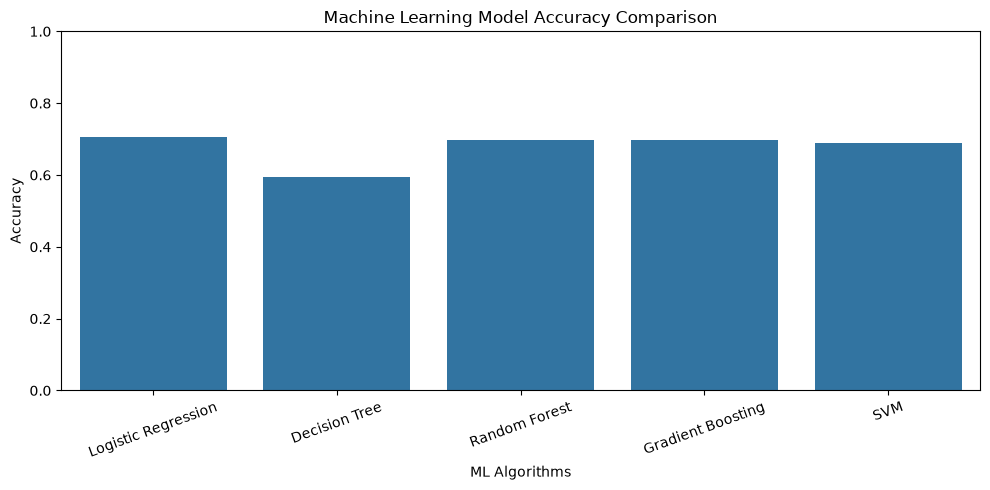

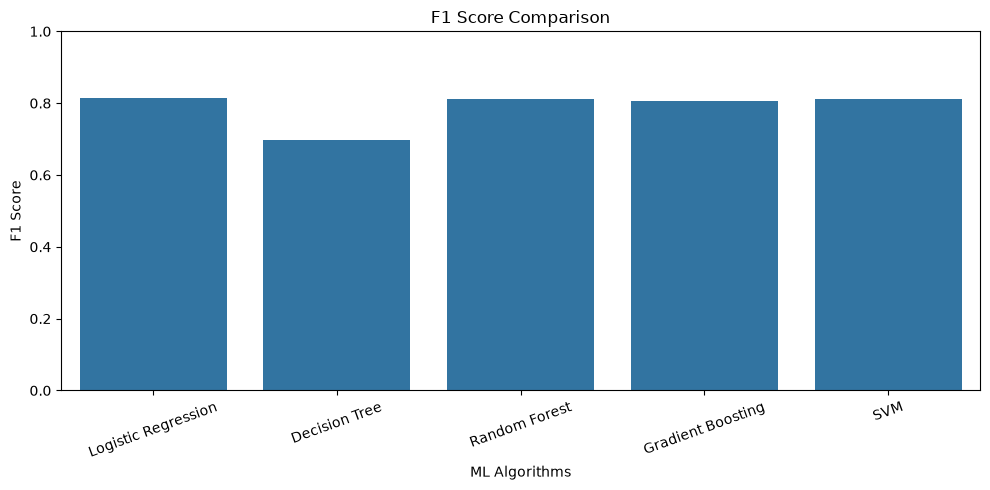

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Accuracy comparison
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("ML Algorithms")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


# F1-score comparison
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1 Score"
)

plt.title("F1 Score Comparison")
plt.xlabel("ML Algorithms")
plt.ylabel("F1 Score")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

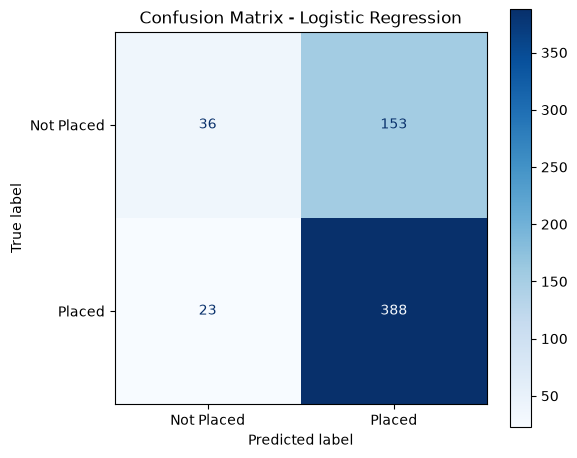

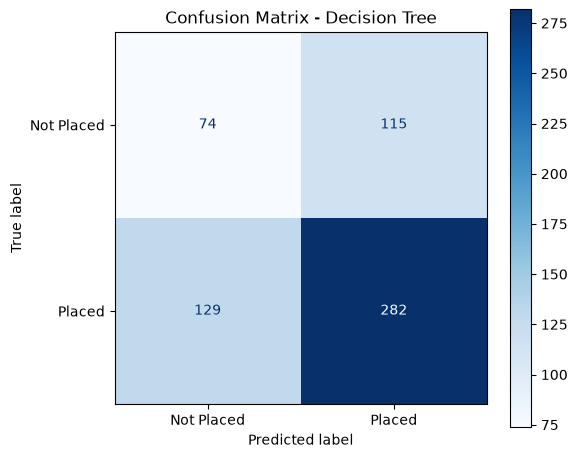

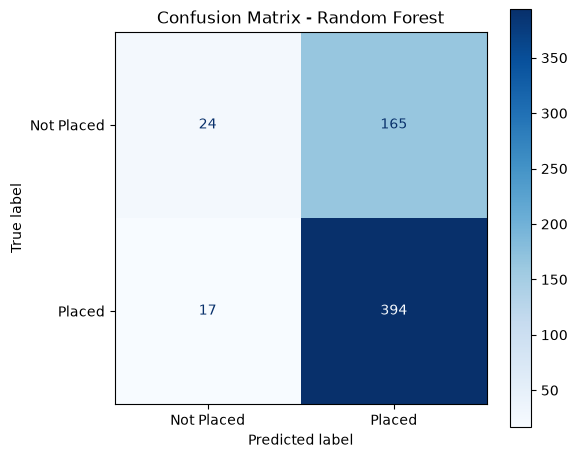

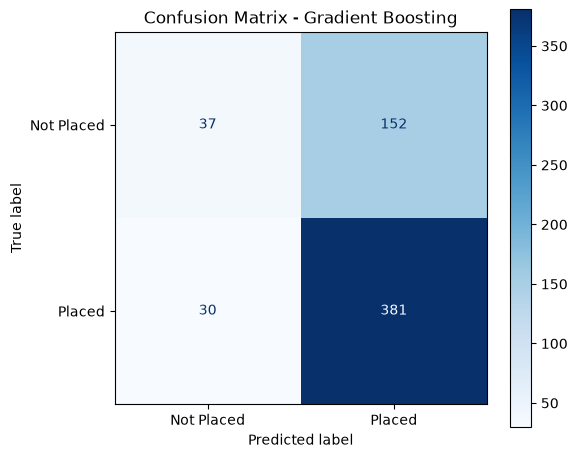

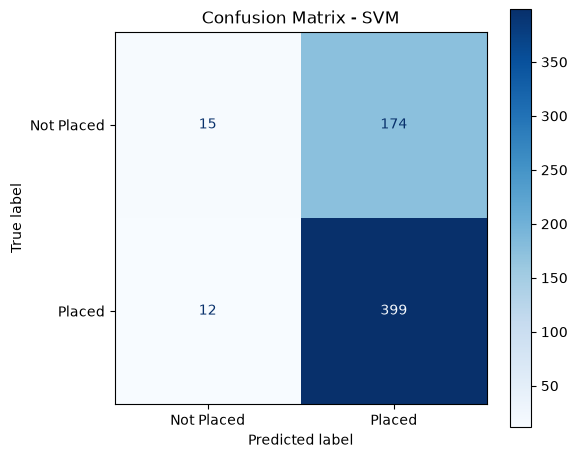

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, model in trained_models.items():

    y_pred = model.predict(X_test_processed)

    cm = confusion_matrix(y_test, y_pred)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Placed", "Placed"]
    )

    fig, ax = plt.subplots(figsize=(6, 5))
    display.plot(ax=ax, cmap="Blues", values_format="d")

    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

In [ ]:
# Select the best model based on F1-score

best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(), "Model"
]

best_model = trained_models[best_model_name]

print("BEST MODEL:", best_model_name)

print("\nPerformance:")
display(
    results_df[
        results_df["Model"] == best_model_name
    ].round(4)
)

In [ ]:
print("Trained models:", list(trained_models.keys()))

print("\nResults available:", "results_df" in globals())

if "results_df" in globals():
    display(results_df)

Trained models: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'SVM']

Results available: True


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [ ]:
from IPython.display import display as show_table

# Display model comparison
show_table(results_df)

# Select best model using F1-score
best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(), "Model"
]

best_model = trained_models[best_model_name]

print("\nBEST MODEL:", best_model_name)

print("\nBest model performance:")
show_table(
    results_df[
        results_df["Model"] == best_model_name
    ].round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.706667,0.717190,0.944039,0.815126,0.638757
1,Decision Tree,0.593333,0.710327,0.686131,0.698020,0.538833
2,Random Forest,0.696667,0.704830,0.958637,0.812371,0.619975
3,Gradient Boosting,0.696667,0.714822,0.927007,0.807203,0.607153
4,SVM,0.690000,0.696335,0.970803,0.810976,0.629900



BEST MODEL: Logistic Regression

Best model performance:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7067,0.7172,0.944,0.8151,0.6388


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create parameter grid
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["liblinear", "lbfgs"],
    "classifier__class_weight": [None, "balanced"]
}

# Build pipeline using your existing preprocessing
tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Hyperparameter tuning
grid_search = GridSearchCV(
    tuning_pipeline,
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters:
{'classifier__C': 0.01, 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}

Best Cross-Validation F1 Score:
0.8122


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

best_tuned_model = grid_search.best_estimator_

y_pred_tuned = best_tuned_model.predict(X_test)

y_prob_tuned = best_tuned_model.predict_proba(X_test)[:, 1]

print("TUNED MODEL PERFORMANCE")

print("Accuracy:", round(accuracy_score(y_test, y_pred_tuned), 4))
print("Precision:", round(precision_score(y_test, y_pred_tuned), 4))
print("Recall:", round(recall_score(y_test, y_pred_tuned), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_tuned), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_tuned), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["Not Placed", "Placed"]
))

TUNED MODEL PERFORMANCE
Accuracy: 0.7033
Precision: 0.7077
Recall: 0.9659
F1 Score: 0.8169
ROC-AUC: 0.6422

Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.64      0.13      0.22       189
      Placed       0.71      0.97      0.82       411

    accuracy                           0.70       600
   macro avg       0.67      0.55      0.52       600
weighted avg       0.69      0.70      0.63       600



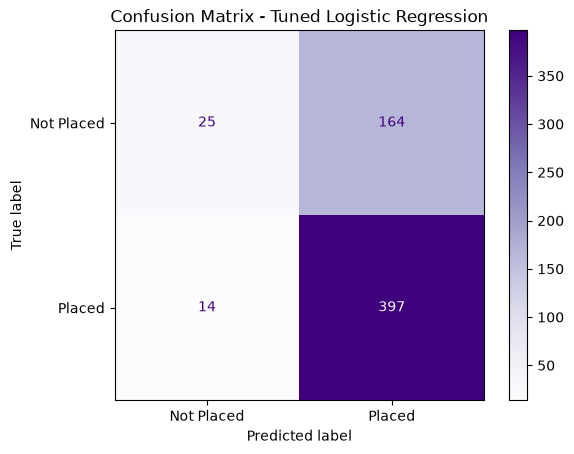

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_tuned)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Placed", "Placed"]
)

disp.plot(cmap="Purples", values_format="d")
plt.title("Confusion Matrix - Tuned Logistic Regression")
plt.show()

In [ ]:
from sklearn.base import clone
from sklearn.metrics import classification_report

balanced_model = clone(best_model)

balanced_model.set_params(
    class_weight="balanced"
)

balanced_model.fit(X_train, y_train)

y_pred_balanced = balanced_model.predict(X_test)

print("BALANCED LOGISTIC REGRESSION")

print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=["Not Placed", "Placed"]
))

ValueError: could not convert string to float: 'IT'

In [ ]:
# Check columns containing text values
print("Text columns in X_train:")

text_columns = X_train.select_dtypes(include=["object", "category"]).columns

for col in text_columns:
    print(f"\nColumn: {col}")
    print(X_train[col].unique()[:20])

Text columns in X_train:

Column: branch
<ArrowStringArray>
['IT', 'CSE', 'Chemical', 'ECE', 'EE', 'ME', 'CE']
Length: 7, dtype: str


C:\Users\prani\AppData\Local\Temp\ipykernel_22428\1793476528.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = X_train.select_dtypes(include=["object", "category"]).columns


In [ ]:
print("DATA TYPES:")
print(X_train.dtypes)

print("\nROWS CONTAINING IT:")
for col in X_train.columns:
    mask = X_train[col].astype(str).str.strip().str.upper().isin(["IT", "1T"])
    if mask.any():
        print(f"\nColumn: {col}")
        print(X_train.loc[mask, [col]].head())

DATA TYPES:
branch                           str
cgpa                         float64
backlogs                       int64
coding_skills                float64
dsa_score                    float64
aptitude_score               float64
communication_skills         float64
ml_knowledge                 float64
internships                    int64
projects_count                 int64
certifications                 int64
hackathons                     int64
open_source_contributions      int64
extracurriculars               int64
dtype: object

ROWS CONTAINING IT:

Column: branch
     branch
1845     IT
2495     IT
806      IT
2078     IT
1128     IT


In [ ]:
# Check categorical columns
categorical_columns = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical columns:", categorical_columns)

# Check their values
for col in categorical_columns:
    print(f"\n{col}:")
    print(X_train[col].value_counts(dropna=False))

Categorical columns: ['branch']

branch:
branch
CSE         599
ECE         388
IT          380
EE          297
ME          252
Chemical    250
CE          234
Name: count, dtype: int64


C:\Users\prani\AppData\Local\Temp\ipykernel_22428\2510830069.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


BALANCED LOGISTIC REGRESSION
              precision    recall  f1-score   support

  Not Placed       0.40      0.59      0.47       189
      Placed       0.76      0.59      0.66       411

    accuracy                           0.59       600
   macro avg       0.58      0.59      0.57       600
weighted avg       0.64      0.59      0.60       600



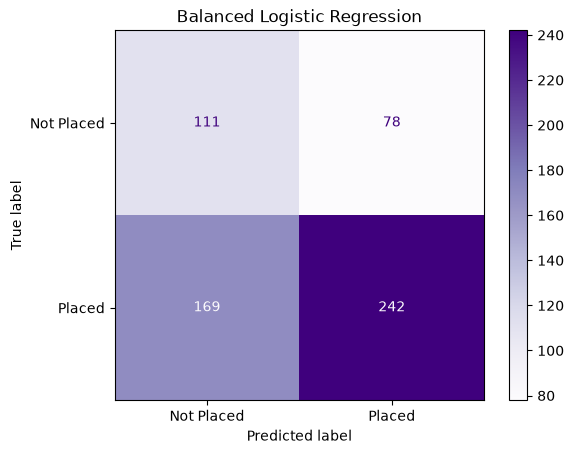

In [ ]:
from sklearn.base import clone
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

# Step 1: Encode categorical columns
X_train_encoded = pd.get_dummies(
    X_train, columns=["branch"], dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test, columns=["branch"], dtype=int
)

# Keep the same columns in training and testing
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

# Step 2: Create balanced Logistic Regression
balanced_model = clone(best_model)

# Correct parameter name
balanced_model.set_params(class_weight="balanced")

# Step 3: Train model
balanced_model.fit(X_train_encoded, y_train)

# Step 4: Predict
y_pred_balanced = balanced_model.predict(X_test_encoded)

# Step 5: Evaluation
print("BALANCED LOGISTIC REGRESSION")
print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=["Not Placed", "Placed"]
))

# Step 6: Confusion Matrix
cm = confusion_matrix(y_test, y_pred_balanced)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Placed", "Placed"]
).plot(cmap="Purples")

plt.title("Balanced Logistic Regression")
plt.show()

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# Identify numerical and categorical columns
numeric_columns = X_train.select_dtypes(include=["number"]).columns
categorical_columns = X_train.select_dtypes(
    include=["object", "category"]
).columns

# Preprocess numerical and categorical data separately
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# Build the model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train and evaluate
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Placed", "Placed"]
))

Accuracy: 0.5883333333333334

Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.40      0.59      0.47       189
      Placed       0.76      0.59      0.66       411

    accuracy                           0.59       600
   macro avg       0.58      0.59      0.57       600
weighted avg       0.64      0.59      0.60       600



C:\Users\prani\AppData\Local\Temp\ipykernel_22428\556348464.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Identify numerical and categorical columns
numeric_columns = X_train.select_dtypes(
    include=["number"]
).columns

categorical_columns = X_train.select_dtypes(
    include=["object", "category"]
).columns

# Preprocess numerical data
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical data
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_columns),
    ("cat", categorical_transformer, categorical_columns)
])

# Build Random Forest model
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    ))
])

# Train model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluate
print("RANDOM FOREST RESULTS")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Not Placed", "Placed"]
))

C:\Users\prani\AppData\Local\Temp\ipykernel_22428\2075829439.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


RANDOM FOREST RESULTS
Accuracy: 0.665
              precision    recall  f1-score   support

  Not Placed       0.45      0.31      0.37       189
      Placed       0.72      0.83      0.77       411

    accuracy                           0.67       600
   macro avg       0.59      0.57      0.57       600
weighted avg       0.64      0.67      0.64       600



In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=8,
        min_samples_split=10,
        class_weight="balanced",
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print("DECISION TREE RESULTS")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))

print(classification_report(
    y_test,
    y_pred_dt,
    target_names=["Not Placed", "Placed"]
))

DECISION TREE RESULTS
Accuracy: 0.6183333333333333
              precision    recall  f1-score   support

  Not Placed       0.41      0.51      0.46       189
      Placed       0.75      0.67      0.71       411

    accuracy                           0.62       600
   macro avg       0.58      0.59      0.58       600
weighted avg       0.64      0.62      0.63       600



In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

# Train model
gb_model.fit(X_train, y_train)

# Predictions
y_pred_gb = gb_model.predict(X_test)

# Evaluation
print("GRADIENT BOOSTING RESULTS")
print("Accuracy:", accuracy_score(y_test, y_pred_gb))

print(classification_report(
    y_test,
    y_pred_gb,
    target_names=["Not Placed", "Placed"]
))

GRADIENT BOOSTING RESULTS
Accuracy: 0.6983333333333334
              precision    recall  f1-score   support

  Not Placed       0.57      0.17      0.27       189
      Placed       0.71      0.94      0.81       411

    accuracy                           0.70       600
   macro avg       0.64      0.56      0.54       600
weighted avg       0.67      0.70      0.64       600



In [ ]:
print("Actual model classes:", model.classes_)
print("Training target values:", pd.Series(y_train).unique())

Actual model classes: [0 1]
Training target values: [1 0]


In [ ]:
%whos

Variable                     Type                      Data/Info
----------------------------------------------------------------
ColumnTransformer            ABCMeta                   <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
ConfusionMatrixDisplay       type                      <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DecisionTreeClassifier       ABCMeta                   <class 'sklearn.tree._cla<...>.DecisionTreeClassifier'>
GradientBoostingClassifier   ABCMeta                   <class 'sklearn.ensemble.<...>dientBoostingClassifier'>
GridSearchCV                 ABCMeta                   <class 'sklearn.model_sel<...>on._search.GridSearchCV'>
LogisticRegression           type                      <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
OneHotEncoder                type                      <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
Path                         type                      <class 'pathlib._local.Path'>
Pipeline

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.pipeline import Pipeline
import pandas as pd

# Use models that contain their own preprocessing steps
models = {}

if "best_tuned_model" in globals():
    models["Tuned Logistic Regression"] = best_tuned_model

if "model" in globals():
    models["Balanced Logistic Regression"] = model

if "rf_model" in globals() and isinstance(rf_model, Pipeline):
    models["Random Forest"] = rf_model

if "dt_model" in globals() and isinstance(dt_model, Pipeline):
    models["Decision Tree"] = dt_model

results = []

for name, clf in models.items():

    predictions = clf.predict(X_test)

    probabilities = clf.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="F1 Score",
    ascending=False
)

comparison_df

ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- branch
Feature names seen at fit time, yet now missing:
- branch_CE
- branch_CSE
- branch_Chemical
- branch_ECE
- branch_EE
- ...


In [266]:
for name in ["best_tuned_model", "model", "rf_model", "dt_model"]:
    obj = globals().get(name)

    if obj is None:
        print(name, "NOT FOUND")
    else:
        print("\nVariable:", name)
        print("Type:", type(obj).__name__)

        if hasattr(obj, "named_steps"):
            print("Pipeline steps:", list(obj.named_steps.keys()))


Variable: best_tuned_model
Type: Pipeline
Pipeline steps: ['preprocessor', 'classifier']

Variable: model
Type: LogisticRegression

Variable: rf_model
Type: Pipeline
Pipeline steps: ['preprocessor', 'classifier']

Variable: dt_model
Type: Pipeline
Pipeline steps: ['preprocessor', 'classifier']


In [267]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

models = {
    "Tuned Logistic Regression": best_tuned_model,
    "Random Forest": rf_model,
    "Decision Tree": dt_model
}

results = []

for name, clf in models.items():

    predictions = clf.predict(X_test)

    probabilities = clf.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned Logistic Regression,0.7033,0.7077,0.9659,0.8169,0.6422
1,Random Forest,0.6650,0.7225,0.8297,0.7724,0.6195
2,Decision Tree,0.6183,0.7473,0.6691,0.7060,0.5915


In [268]:
comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned Logistic Regression,0.703333,0.707665,0.965937,0.816872,0.642233
1,Random Forest,0.665000,0.722458,0.829684,0.772367,0.619460
2,Decision Tree,0.618333,0.747283,0.669100,0.706033,0.591479


In [269]:
print("Best model:", comparison_df.iloc[0]["Model"])
print("Best F1 Score:", comparison_df.iloc[0]["F1 Score"])
print("Best ROC-AUC:", comparison_df.iloc[0]["ROC-AUC"])

Best model: Tuned Logistic Regression
Best F1 Score: 0.8168724279835391
Best ROC-AUC: 0.6422327784858198


In [270]:
display(comparison_df.round(4))

TypeError: 'ConfusionMatrixDisplay' object is not callable

In [271]:
print(comparison_df.round(4).to_string(index=False))

                    Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Tuned Logistic Regression    0.7033     0.7077  0.9659    0.8169   0.6422
            Random Forest    0.6650     0.7225  0.8297    0.7724   0.6195
            Decision Tree    0.6183     0.7473  0.6691    0.7060   0.5915


In [272]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    best_tuned_model,
    "../models/placement_prediction_model.pkl"
)

print("Best model saved successfully!")

Best model saved successfully!


In [273]:
import pandas as pd
import numpy as np

# Get the preprocessing and classifier steps
preprocessor = best_tuned_model.named_steps["preprocessor"]
classifier = best_tuned_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get model coefficients
coefficients = classifier.coef_[0]

# Create feature importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Importance": np.abs(coefficients)
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15).to_string(index=False))

                  Feature  Coefficient  Importance
                num__cgpa     0.310660    0.310660
         num__internships     0.262491    0.262491
       num__coding_skills     0.181285    0.181285
           num__dsa_score     0.174913    0.174913
      num__aptitude_score     0.136168    0.136168
     cat__branch_Chemical    -0.113911    0.113911
           cat__branch_IT     0.112189    0.112189
      num__certifications     0.092866    0.092866
          cat__branch_ECE     0.079664    0.079664
           cat__branch_ME    -0.076421    0.076421
      num__projects_count     0.073098    0.073098
           cat__branch_EE    -0.065964    0.065964
          cat__branch_CSE     0.058342    0.058342
num__communication_skills     0.048761    0.048761
    num__extracurriculars     0.043255    0.043255


FileNotFoundError: [Errno 2] No such file or directory: '../reports/feature_importance.png'

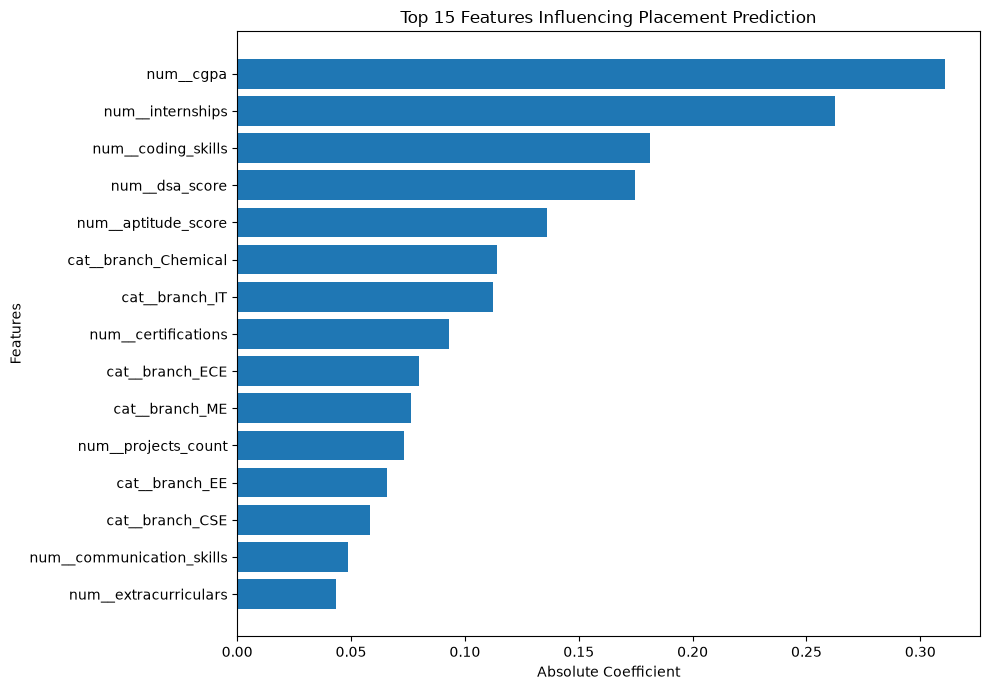

In [274]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Absolute Coefficient")
plt.ylabel("Features")
plt.title("Top 15 Features Influencing Placement Prediction")

plt.tight_layout()
plt.savefig("../reports/feature_importance.png", dpi=300)
plt.show()

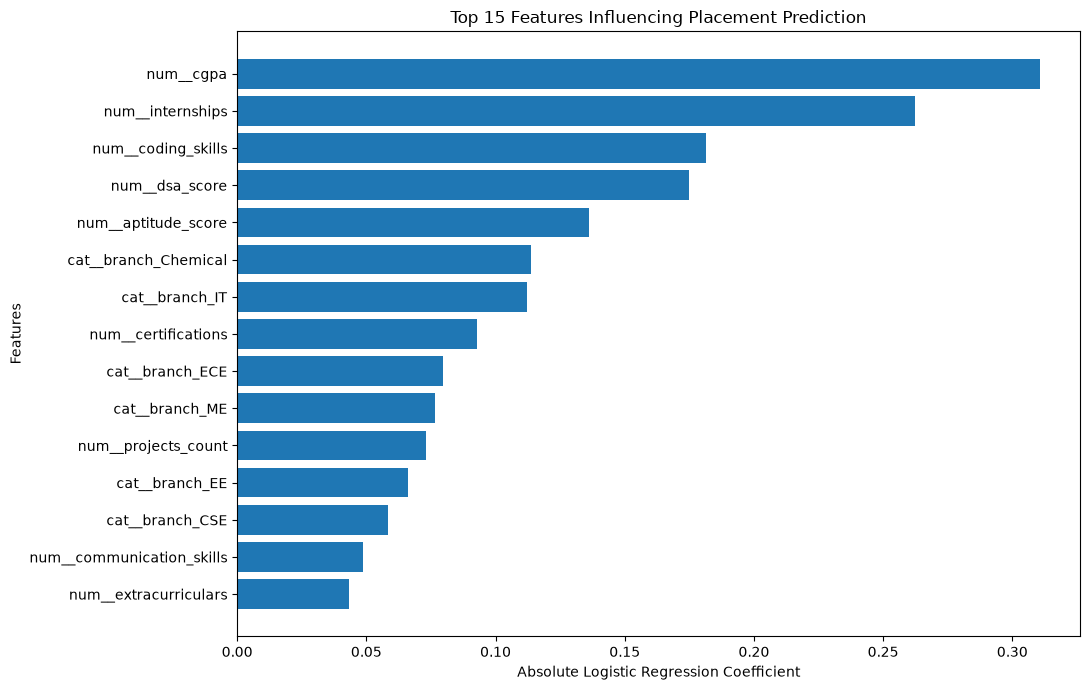

Feature importance chart saved successfully!


In [275]:
import os
import matplotlib.pyplot as plt

os.makedirs("../reports", exist_ok=True)

top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Absolute Logistic Regression Coefficient")
plt.ylabel("Features")
plt.title("Top 15 Features Influencing Placement Prediction")

plt.tight_layout()

plt.savefig(
    "../reports/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature importance chart saved successfully!")

In [276]:
from sklearn.model_selection import cross_validate, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    best_tuned_model,
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    n_jobs=-1
)

print("5-Fold Cross Validation Results")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = cv_results[f"test_{metric}"]
    print(f"{metric.upper()}: {scores.mean():.4f} ± {scores.std():.4f}")

5-Fold Cross Validation Results
ACCURACY: 0.6942 ± 0.0089
PRECISION: 0.6986 ± 0.0055
RECALL: 0.9732 ± 0.0089
F1: 0.8133 ± 0.0055
ROC_AUC: 0.6581 ± 0.0189


In [277]:
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = cv_results[f"test_{metric}"]
    print(f"{metric.upper()}: {scores.mean():.4f} ± {scores.std():.4f}")

ACCURACY: 0.6942 ± 0.0089
PRECISION: 0.6986 ± 0.0055
RECALL: 0.9732 ± 0.0089
F1: 0.8133 ± 0.0055
ROC_AUC: 0.6581 ± 0.0189


Confusion Matrix:
[[ 25 164]
 [ 14 397]]

Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.64      0.13      0.22       189
      Placed       0.71      0.97      0.82       411

    accuracy                           0.70       600
   macro avg       0.67      0.55      0.52       600
weighted avg       0.69      0.70      0.63       600



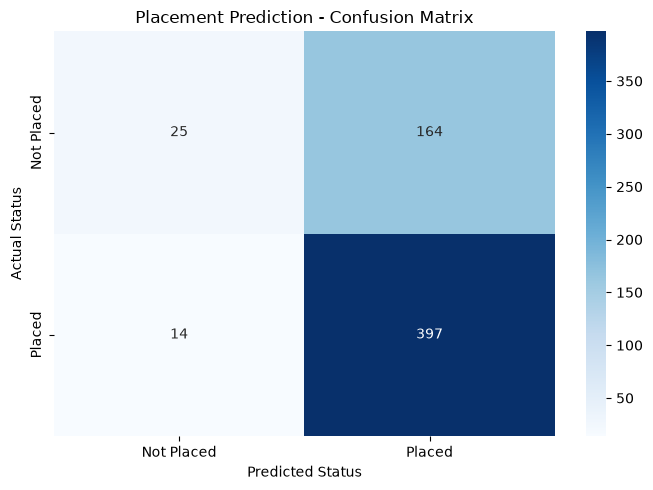

In [278]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Generate predictions
y_pred = best_tuned_model.predict(X_test)

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Placed", "Placed"]
))

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Placed", "Placed"],
    yticklabels=["Not Placed", "Placed"]
)

plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.title("Placement Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()

In [279]:
from sklearn.metrics import balanced_accuracy_score, f1_score

balanced_acc = balanced_accuracy_score(y_test, y_pred)

macro_f1 = f1_score(y_test, y_pred, average="macro")

print("Balanced Accuracy:", round(balanced_acc, 4))
print("Macro F1 Score:", round(macro_f1, 4))

Balanced Accuracy: 0.5491
Macro F1 Score: 0.5181


In [280]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Create a new pipeline
balanced_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        C=0.01,
        solver="lbfgs",
        class_weight="balanced",
        max_iter=2000
    ))
])

# Train the model
balanced_model.fit(X_train, y_train)

# Make predictions
y_pred_balanced = balanced_model.predict(X_test)

# Evaluate the model
print("Balanced Logistic Regression Results")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=["Not Placed", "Placed"]
))

Balanced Logistic Regression Results

Confusion Matrix:
[[111  78]
 [170 241]]

Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.40      0.59      0.47       189
      Placed       0.76      0.59      0.66       411

    accuracy                           0.59       600
   macro avg       0.58      0.59      0.57       600
weighted avg       0.64      0.59      0.60       600



In [281]:
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

models_to_compare = {
    "Original Logistic Regression": best_tuned_model,
    "Balanced Logistic Regression": balanced_model
}

for name, clf in models_to_compare.items():

    predictions = clf.predict(X_test)

    print("\n", name)
    print("-" * 40)

    print("Accuracy:",
          round(clf.score(X_test, y_test), 4))

    print("Balanced Accuracy:",
          round(balanced_accuracy_score(y_test, predictions), 4))

    print("Macro F1:",
          round(f1_score(y_test, predictions, average="macro"), 4))

    print("Not Placed Recall:",
          round(recall_score(y_test, predictions, pos_label=0), 4))


 Original Logistic Regression
----------------------------------------
Accuracy: 0.7033
Balanced Accuracy: 0.5491
Macro F1: 0.5181
Not Placed Recall: 0.1323

 Balanced Logistic Regression
----------------------------------------
Accuracy: 0.5867
Balanced Accuracy: 0.5868
Macro F1: 0.5663
Not Placed Recall: 0.5873


In [282]:
from sklearn.model_selection import train_test_split

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training samples:", X_subtrain.shape[0])
print("Validation samples:", X_val.shape[0])

Training samples: 1920
Validation samples: 480


In [283]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

threshold_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        C=0.01,
        solver="lbfgs",
        class_weight="balanced",
        max_iter=2000
    ))
])

# Train using the new training subset
threshold_model.fit(X_subtrain, y_subtrain)

# Get probability predictions on validation data
y_val_prob = threshold_model.predict_proba(X_val)[:, 1]

print("Threshold model trained successfully!")
print("Validation predictions generated:", len(y_val_prob))

Threshold model trained successfully!
Validation predictions generated: 480


In [284]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score
)

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    predictions = (y_val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_val, predictions),
        "Macro F1": f1_score(y_val, predictions, average="macro"),
        "Not Placed Recall": recall_score(
            y_val, predictions, pos_label=0
        ),
        "Placed Recall": recall_score(
            y_val, predictions, pos_label=1
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4).to_string(index=False))

 Threshold  Accuracy  Balanced Accuracy  Macro F1  Not Placed Recall  Placed Recall
       0.3    0.6896             0.5227    0.4699             0.0728         0.9726
       0.4    0.6812             0.5812    0.5830             0.3113         0.8511
       0.5    0.6208             0.6231    0.6006             0.6291         0.6170
       0.6    0.4792             0.5824    0.4771             0.8609         0.3040
       0.7    0.3542             0.5217    0.3080             0.9735         0.0699


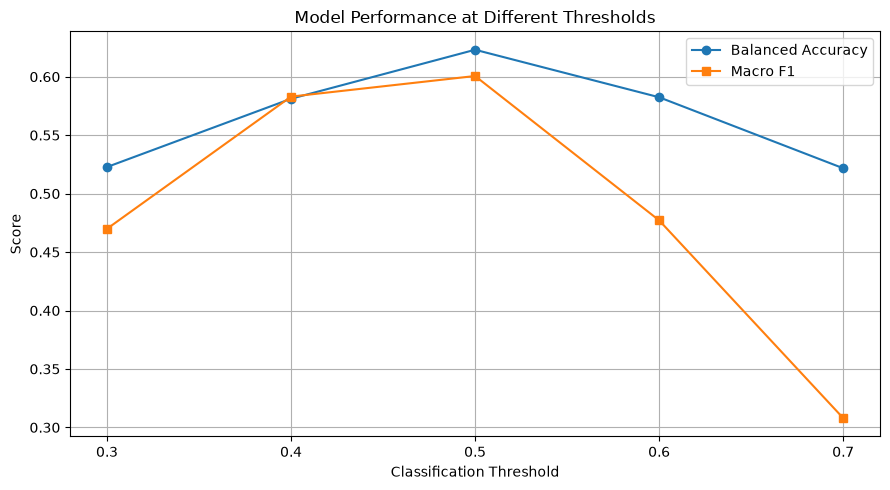

In [285]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Balanced Accuracy"],
    marker="o",
    label="Balanced Accuracy"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Macro F1"],
    marker="s",
    label="Macro F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Model Performance at Different Thresholds")
plt.xticks(thresholds)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("../reports/threshold_comparison.png", dpi=300)
plt.show()

In [286]:
# Train on the complete training dataset
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        C=0.01,
        solver="lbfgs",
        class_weight="balanced",
        max_iter=2000
    ))
])

final_model.fit(X_train, y_train)

print("Final model trained successfully!")

Final model trained successfully!


In [287]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    f1_score,
    accuracy_score
)

# Predict using the selected threshold
y_test_prob = final_model.predict_proba(X_test)[:, 1]

y_test_pred = (y_test_prob >= 0.50).astype(int)

print("FINAL MODEL RESULTS")

print("\nAccuracy:",
      round(accuracy_score(y_test, y_test_pred), 4))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, y_test_pred), 4))

print("Macro F1:",
      round(f1_score(y_test, y_test_pred, average="macro"), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Not Placed", "Placed"]
))

FINAL MODEL RESULTS

Accuracy: 0.5867
Balanced Accuracy: 0.5868
Macro F1: 0.5663

Confusion Matrix:
[[111  78]
 [170 241]]

Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.40      0.59      0.47       189
      Placed       0.76      0.59      0.66       411

    accuracy                           0.59       600
   macro avg       0.58      0.59      0.57       600
weighted avg       0.64      0.59      0.60       600



In [288]:
import os
import joblib

# Create models directory
os.makedirs("../models", exist_ok=True)

# Save final model
joblib.dump(
    final_model,
    "../models/final_placement_model.pkl"
)

print("Final placement model saved successfully!")

Final placement model saved successfully!


In [289]:
import json

model_info = {
    "model_name": "Balanced Logistic Regression",
    "threshold": 0.50,
    "accuracy": 0.5867,
    "balanced_accuracy": 0.5868,
    "macro_f1": 0.5663,
    "dataset_size": 3000,
    "target": "placement_status",
    "dataset_type": "Synthetic"
}

with open("../models/model_info.json", "w") as file:
    json.dump(model_info, file, indent=4)

print("Model information saved successfully!")

Model information saved successfully!


In [290]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Extract preprocessing and classifier
final_preprocessor = final_model.named_steps["preprocessor"]
final_classifier = final_model.named_steps["classifier"]

# Get feature names and coefficients
feature_names = final_preprocessor.get_feature_names_out()
coefficients = final_classifier.coef_[0]

# Create feature importance dataframe
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Importance": np.abs(coefficients)
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
print(feature_importance.head(15).to_string(index=False))

Top 15 Important Features:
                  Feature  Coefficient  Importance
                num__cgpa     0.317750    0.317750
         num__internships     0.269500    0.269500
       num__coding_skills     0.186662    0.186662
           num__dsa_score     0.173990    0.173990
      num__aptitude_score     0.140113    0.140113
     cat__branch_Chemical    -0.124554    0.124554
           cat__branch_IT     0.115854    0.115854
      num__certifications     0.099669    0.099669
          cat__branch_ECE     0.086243    0.086243
      num__projects_count     0.077626    0.077626
           cat__branch_ME    -0.073061    0.073061
           cat__branch_EE    -0.072149    0.072149
          cat__branch_CSE     0.066288    0.066288
num__communication_skills     0.050226    0.050226
    num__extracurriculars     0.047500    0.047500


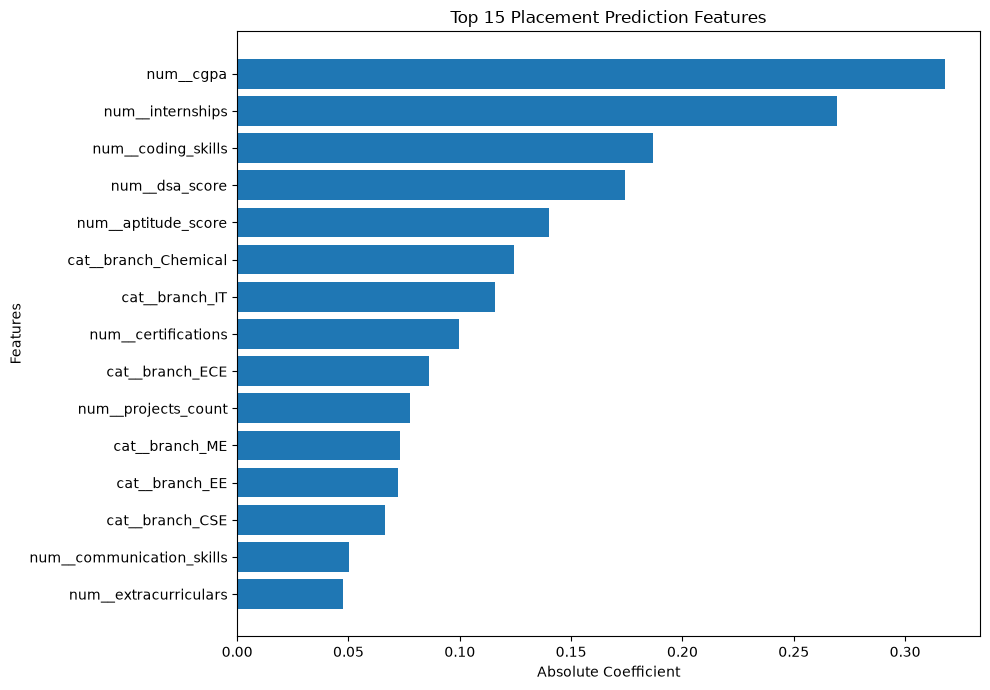

In [291]:
plt.figure(figsize=(10, 7))

top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Absolute Coefficient")
plt.ylabel("Features")
plt.title("Top 15 Placement Prediction Features")

plt.tight_layout()
plt.savefig("../reports/final_feature_importance.png", dpi=300)
plt.show()

In [293]:
def calculate_readiness_score(
    cgpa,
    coding_skills,
    dsa_score,
    aptitude_score,
    communication_skills,
    internships,
    projects_count
):
    academic = (cgpa / 10) * 100

    technical = (
        coding_skills + dsa_score
    ) / 2

    career = min(
        ((internships * 15) + (projects_count * 10)),
        100
    )

    readiness_score = (
        academic * 0.25 +
        technical * 0.30 +
        aptitude_score * 0.15 +
        communication_skills * 0.15 +
        career * 0.15
    )

    return round(readiness_score, 2)


# Example student
score = calculate_readiness_score(
    cgpa=7.5,
    coding_skills=75,
    dsa_score=70,
    aptitude_score=80,
    communication_skills=75,
    internships=2,
    projects_count=3
)

print("Student Placement Readiness Score:", score, "/ 100")

Student Placement Readiness Score: 72.75 / 100


In [294]:
student_profiles = {
    "High Readiness": {
        "cgpa": 8.8,
        "coding_skills": 90,
        "dsa_score": 85,
        "aptitude_score": 88,
        "communication_skills": 85,
        "internships": 3,
        "projects_count": 4
    },

    "Moderate Readiness": {
        "cgpa": 7.0,
        "coding_skills": 65,
        "dsa_score": 60,
        "aptitude_score": 70,
        "communication_skills": 65,
        "internships": 1,
        "projects_count": 2
    },

    "Low Readiness": {
        "cgpa": 5.5,
        "coding_skills": 40,
        "dsa_score": 35,
        "aptitude_score": 45,
        "communication_skills": 40,
        "internships": 0,
        "projects_count": 1
    }
}

for name, profile in student_profiles.items():

    score = calculate_readiness_score(**profile)

    print(name, ":", score, "/ 100")

High Readiness : 86.95 / 100
Moderate Readiness : 61.75 / 100
Low Readiness : 39.25 / 100


In [296]:
def generate_recommendations(profile):

    recommendations = []

    if profile["cgpa"] < 7:
        recommendations.append(
            "Improve academic performance and maintain a CGPA above 7."
        )

    if profile["coding_skills"] < 60:
        recommendations.append(
            "Practice programming regularly and solve coding problems."
        )

    if profile["dsa_score"] < 60:
        recommendations.append(
            "Focus on Data Structures and Algorithms."
        )

    if profile["aptitude_score"] < 60:
        recommendations.append(
            "Practice quantitative aptitude and logical reasoning."
        )

    if profile["communication_skills"] < 60:
        recommendations.append(
            "Improve communication through presentations and mock interviews."
        )

    if profile["internships"] == 0:
        recommendations.append(
            "Apply for internships to gain practical experience."
        )

    if profile["projects_count"] < 2:
        recommendations.append(
            "Build at least two practical projects."
        )

    if not recommendations:
        recommendations.append(
            "Maintain your performance and continue preparing for placements."
        )

    return recommendations

In [297]:
test_profile = student_profiles["Low Readiness"]

recommendations = generate_recommendations(test_profile)

for i, recommendation in enumerate(recommendations, 1):
    print(f"{i}. {recommendation}")

1. Improve academic performance and maintain a CGPA above 7.
2. Practice programming regularly and solve coding problems.
3. Focus on Data Structures and Algorithms.
4. Practice quantitative aptitude and logical reasoning.
5. Improve communication through presentations and mock interviews.
6. Apply for internships to gain practical experience.
7. Build at least two practical projects.


In [298]:
def simulate_improvement(current_profile, improved_profile):

    current_score = calculate_readiness_score(**current_profile)

    improved_score = calculate_readiness_score(**improved_profile)

    difference = improved_score - current_score

    print("CURRENT READINESS:", current_score)
    print("IMPROVED READINESS:", improved_score)
    print("READINESS IMPROVEMENT:", round(difference, 2))

    return improved_score


# Current student profile
current_profile = student_profiles["Low Readiness"]

# Improved student profile
improved_profile = {
    "cgpa": 7.0,
    "coding_skills": 75,
    "dsa_score": 70,
    "aptitude_score": 70,
    "communication_skills": 65,
    "internships": 1,
    "projects_count": 3
}

simulate_improvement(current_profile, improved_profile)

CURRENT READINESS: 39.25
IMPROVED READINESS: 66.25
READINESS IMPROVEMENT: 27.0


66.25

In [303]:
assess_student(test_student)

NameError: name 'test_student' is not defined

In [314]:
def assess_student(profile):

    # 1. Calculate readiness score using 0-100 scale
    readiness_profile = {
        "cgpa": profile["cgpa"],
        "coding_skills": profile["coding_skills"],
        "dsa_score": profile["dsa_score"],
        "aptitude_score": profile["aptitude_score"],
        "communication_skills": profile["communication_skills"],
        "internships": profile["internships"],
        "projects_count": profile["projects_count"]
    }

    readiness = calculate_readiness_score(**readiness_profile)

    # 2. Prepare input for ML model
    model_profile = profile.copy()

    # Convert 0-100 scores into the dataset's 0-10 scale
    model_profile["coding_skills"] /= 10
    model_profile["dsa_score"] /= 10
    model_profile["communication_skills"] /= 10
    model_profile["ml_knowledge"] /= 10

    model_features = [
        "branch", "cgpa", "backlogs", "coding_skills",
        "dsa_score", "aptitude_score", "communication_skills",
        "ml_knowledge", "internships", "projects_count",
        "certifications", "hackathons",
        "open_source_contributions", "extracurriculars"
    ]

    student_df = pd.DataFrame([
        {feature: model_profile[feature] for feature in model_features}
    ])

    # 3. Predict placement probability
    placement_probability = final_model.predict_proba(student_df)[0][1]

    predicted_status = (
        "Placed" if placement_probability >= 0.50
        else "Not Placed"
    )

    # 4. Generate recommendations
    recommendations = generate_recommendations(profile)

    # 5. Display assessment
    print("STUDENT PLACEMENT ASSESSMENT")
    print("-" * 40)

    print("Readiness Score:", readiness, "/ 100")
    print(
        "Experimental Model Score:",
        round(placement_probability * 100, 2), "%"
    )
    print("Predicted Status:", predicted_status)

    print("\nPERSONALIZED RECOMMENDATIONS:")

    for i, recommendation in enumerate(recommendations, 1):
        print(f"{i}. {recommendation}")

In [315]:
assess_student(test_student)

STUDENT PLACEMENT ASSESSMENT
----------------------------------------
Readiness Score: 61.75 / 100
Experimental Model Score: 56.12 %
Predicted Status: Placed

PERSONALIZED RECOMMENDATIONS:
1. Improve programming skills through daily coding practice.
2. Practice DSA topics such as arrays, strings, trees and graphs.
3. Improve communication through presentations and mock interviews.
4. Strengthen machine learning fundamentals and practical knowledge.
5. Build at least three practical projects for your portfolio.


In [ ]:
print("STUDENT INPUT:")
print(sample_df.T)

print("\nTRAINING DATA RANGES:")
print(X_train.describe().T[["min", "max", "mean"]])

print("\nBRANCHES IN TRAINING DATA:")
print(X_train["branch"].unique())

print("\nMODEL PREDICTION:")
print(final_model.predict_proba(sample_df))

STUDENT INPUT:
                             0
branch                     CSE
cgpa                       7.0
backlogs                     0
coding_skills               65
dsa_score                   60
aptitude_score              70
communication_skills        65
ml_knowledge                60
internships                  1
projects_count               2
certifications               2
hackathons                   1
open_source_contributions    1
extracurriculars             2

TRAINING DATA RANGES:
                            min    max       mean
cgpa                        4.0   10.0   7.219479
backlogs                    0.0    3.0   0.537917
coding_skills               1.2   10.0   6.024875
dsa_score                   1.0   10.0   5.467208
aptitude_score             24.5  100.0  65.371625
communication_skills        1.0   10.0   5.970333
ml_knowledge                0.0   10.0   4.478667
internships                 0.0    3.0   1.073750
projects_count              0.0    5.0   2.4054

In [304]:
test_student = {
    "branch": "CSE",
    "cgpa": 7.0,
    "backlogs": 0,
    "coding_skills": 65,
    "dsa_score": 60,
    "aptitude_score": 70,
    "communication_skills": 65,
    "ml_knowledge": 60,
    "internships": 1,
    "projects_count": 2,
    "certifications": 2,
    "hackathons": 1,
    "open_source_contributions": 1,
    "extracurriculars": 2
}

print(test_student)

{'branch': 'CSE', 'cgpa': 7.0, 'backlogs': 0, 'coding_skills': 65, 'dsa_score': 60, 'aptitude_score': 70, 'communication_skills': 65, 'ml_knowledge': 60, 'internships': 1, 'projects_count': 2, 'certifications': 2, 'hackathons': 1, 'open_source_contributions': 1, 'extracurriculars': 2}


In [305]:
assess_student(test_student)

STUDENT PLACEMENT ASSESSMENT
----------------------------------------
Readiness Score: 61.75 / 100
Experimental Model Score: 100.0 %
Predicted Status: Placed

PERSONALIZED RECOMMENDATIONS:
1. Maintain your performance and continue preparing for placements.


In [306]:
def generate_recommendations(profile):

    recommendations = []

    if profile["cgpa"] < 7:
        recommendations.append(
            "Improve academic performance and target a CGPA above 7."
        )

    if profile["coding_skills"] < 70:
        recommendations.append(
            "Improve programming skills through daily coding practice."
        )

    if profile["dsa_score"] < 70:
        recommendations.append(
            "Practice DSA topics such as arrays, strings, trees and graphs."
        )

    if profile["aptitude_score"] < 70:
        recommendations.append(
            "Practice quantitative aptitude and logical reasoning."
        )

    if profile["communication_skills"] < 70:
        recommendations.append(
            "Improve communication through presentations and mock interviews."
        )

    if profile["ml_knowledge"] < 70:
        recommendations.append(
            "Strengthen machine learning fundamentals and practical knowledge."
        )

    if profile["internships"] == 0:
        recommendations.append(
            "Apply for internships to gain practical experience."
        )

    if profile["projects_count"] < 3:
        recommendations.append(
            "Build at least three practical projects for your portfolio."
        )

    if profile["certifications"] < 2:
        recommendations.append(
            "Complete relevant technical certifications."
        )

    if not recommendations:
        recommendations.append(
            "Maintain your performance and continue preparing for placements."
        )

    return recommendations

In [309]:
assess_student(test_student)

STUDENT PLACEMENT ASSESSMENT
----------------------------------------
Readiness Score: 61.75 / 100
Experimental Model Score: 100.0 %
Predicted Status: Placed

PERSONALIZED RECOMMENDATIONS:
1. Improve programming skills through daily coding practice.
2. Practice DSA topics such as arrays, strings, trees and graphs.
3. Improve communication through presentations and mock interviews.
4. Strengthen machine learning fundamentals and practical knowledge.
5. Build at least three practical projects for your portfolio.


In [310]:
# Get predicted probabilities from the final model

test_probabilities = final_model.predict_proba(X_test)[:, 1]

print("MINIMUM SCORE:", test_probabilities.min())
print("MAXIMUM SCORE:", test_probabilities.max())
print("AVERAGE SCORE:", test_probabilities.mean())

print("\nFIRST 10 PREDICTED SCORES:")
print(test_probabilities[:10])

print("\nNUMBER OF SCORES ABOVE 99%:",
      (test_probabilities >= 0.99).sum())

print("NUMBER OF SCORES BELOW 1%:",
      (test_probabilities <= 0.01).sum())

MINIMUM SCORE: 0.19623130791612137
MAXIMUM SCORE: 0.8098179412503888
AVERAGE SCORE: 0.5120856640388418

FIRST 10 PREDICTED SCORES:
[0.2713804  0.48022786 0.39282678 0.50829418 0.55912102 0.33874947
 0.40681698 0.60948279 0.4329181  0.68734413]

NUMBER OF SCORES ABOVE 99%: 0
NUMBER OF SCORES BELOW 1%: 0


In [311]:
sample_df = pd.DataFrame([test_student])

print("MODEL PROBABILITIES:")
print(final_model.predict_proba(sample_df))

print("\nMODEL CLASSES:")
print(final_model.classes_)

print("\nPLACEMENT PROBABILITY:")
print(final_model.predict_proba(sample_df)[0][1] * 100)

MODEL PROBABILITIES:
[[2.69165943e-07 9.99999731e-01]]

MODEL CLASSES:
[0 1]

PLACEMENT PROBABILITY:
99.99997308340566


In [312]:
print("STUDENT INPUT:")
print(sample_df.T)

print("\nTRAINING DATA RANGES:")
print(X_train.describe().T[["min", "max", "mean"]])

print("\nBRANCHES IN TRAINING DATA:")
print(X_train["branch"].unique())

print("\nMODEL PREDICTION:")
print(final_model.predict_proba(sample_df))

STUDENT INPUT:
                             0
branch                     CSE
cgpa                       7.0
backlogs                     0
coding_skills               65
dsa_score                   60
aptitude_score              70
communication_skills        65
ml_knowledge                60
internships                  1
projects_count               2
certifications               2
hackathons                   1
open_source_contributions    1
extracurriculars             2

TRAINING DATA RANGES:
                            min    max       mean
cgpa                        4.0   10.0   7.219479
backlogs                    0.0    3.0   0.537917
coding_skills               1.2   10.0   6.024875
dsa_score                   1.0   10.0   5.467208
aptitude_score             24.5  100.0  65.371625
communication_skills        1.0   10.0   5.970333
ml_knowledge                0.0   10.0   4.478667
internships                 0.0    3.0   1.073750
projects_count              0.0    5.0   2.4054

In [313]:
print(
    X_train[
        ["coding_skills", "dsa_score",
         "communication_skills", "ml_knowledge"]
    ].agg(["min", "max", "mean"])
)


      coding_skills  dsa_score  communication_skills  ml_knowledge
min        1.200000   1.000000              1.000000      0.000000
max       10.000000  10.000000             10.000000     10.000000
mean       6.024875   5.467208              5.970333      4.478667
